In [5]:
from src import utils, argparser, linear_RNN, theory, plotting
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import math

In [6]:
bc = plotting.BlindColours()
blind_colors = bc.get_colours()
div_cmap = bc.get_div_cmap()

In [14]:
parser = argparser.get_parser()  
args = parser.parse_args('')
args.frozen_input_output = True
args.frozen_hidden_layer = False
args.input_size = 3
args.hidden_size = 3
args.output_size = 3
args.num_seeds = 1
args.num_SV = 3
args.trajectory_length= 3
args.inout_mode_init = [0.7, 1, (1/(1.1**args.trajectory_length))]
args.rec_mode_init = [.1, .1, .1] #[0.3,0.3]
args.lr = 5
args.num_epochs = 10000

In [15]:
S = torch.zeros((args.trajectory_length, args.output_size, args.input_size)) 
for t in range(1, args.trajectory_length+1):
    t_S = torch.tensor([0.7, 0.7**(args.trajectory_length-t), 1.1**t]) #  0.7**t, 
#     t_S = torch.tensor([1., 1., 1.])
    S[t-1] = torch.diag(t_S) 
    # soln for b at [1, 0.7, 1/1.1 ~0.9]
args.S = S
args.num_seeds = 1

args, X, y = utils.generate_data(args)

tape = utils.get_tape_module(args)

args.inout_mode_init = torch.tensor(args.inout_mode_init)
args.rec_mode_init = torch.tensor(args.rec_mode_init)

W_x, W_h, W_y, dW_x, dW_h, dW_y, R_y, R_x = utils.initialize_student(args)

tape.W_x[0,0] = W_x.detach().numpy()
tape.W_h[0,0] = W_h.detach().numpy()
tape.W_y[0,0] = W_y.detach().numpy()
tape.dW_x[0,0] = dW_x.detach().numpy()
tape.dW_h[0,0] = dW_h.detach().numpy()
tape.dW_y[0,0] = dW_y.detach().numpy()
tape.R_y[0,0] = R_y.detach().numpy()
tape.R_x[0,0] = R_x.detach().numpy()

tensor(0.8642)


In [16]:
model = linear_RNN.LinearRNN(args, init_W_x = W_x, init_W_h = W_h, init_W_y = W_y)
losses, W_x_ar, W_h_ar, W_y_ar, H_ar, W_x_grad_ar, W_h_grad_ar = model.train(X,y) ## add tape to model
a_sim,b_sim,c_sim,u_sim = model.project_SVD_space(W_x_ar, W_h_ar, W_y_ar, tape)

In [17]:
def recurrent_solution(args): 
    tau = (args.num_samples*args.output_size)/args.lr
    T = args.trajectory_length
    b_pred = np.zeros((args.num_SV, args.num_epochs))
    for e in range(0, args.num_epochs):
        for alpha in range(args.num_SV):
            b = args.rec_mode_init[alpha]
            if e == 0:
                b_pred[alpha,e] = b
            else:
                u = args.inout_mode_init[alpha]
                sum_term = 0
                for n in range(1,T): #N
                    inner_sum_term = 0
                    for i in range(1, T-n+1):
                        if n == 1:
                            inner_sum_term += (T-i)*u*args.S[i-1, alpha, alpha]*(b**(T-i-1))
                            inner_sum_term -= (T-i)*(u**2)*(b**(2*T-2*i-1))
                        else:
                            inner_sum_term += (math.factorial(T-i)/math.factorial(T-i-n))*u*args.S[i-1, alpha, alpha]*(b**(T-i-n))
                            inner_sum_term -= (((T-i)*math.factorial(2*T-2*i-1))/(math.factorial(2*T-2*i-n)))*(u**2)*(b**(2*T-2*i-n))
                    sum_term += (inner_sum_term * ((e/tau)**n)/(math.factorial(n)))
                b_pred[alpha,e] = b + sum_term
    return b_pred

In [18]:
def recurrent_solution_2(args): 
    tau = (args.num_samples*args.output_size)/args.lr
    T = args.trajectory_length
    b_pred = np.zeros((args.num_SV, args.num_epochs))
    for e in range(0, args.num_epochs):
        for alpha in range(args.num_SV):
            b = args.rec_mode_init[alpha]
            if e == 0:
                b_pred[alpha,e] = b
            else:
                u = args.inout_mode_init[alpha]
                sum_term = 0
                db_dt = 0
                df_db = 0
                d2f_db2 = 0
                for n in range(1,4): #T): #N
                    inner_sum_term = 0
                    for i in range(1, T-n+1):
                        if n == 1: # order 1
                            db_dt += (T-i)*u*args.S[i-1, alpha, alpha]*(b**(T-i-1))
                            db_dt -= (T-i)*(u**2)*(b**(2*T-2*i-1))
#                             inner_sum_term += (T-i)*u*args.S[i-1, alpha, alpha]*(b**(T-i-1))
#                             inner_sum_term -= (T-i)*(u**2)*(b**(2*T-2*i-1))
                        elif n == 2:
                            df_db += (math.factorial(T-i)/math.factorial(T-i-n))*u*args.S[i-1, alpha, alpha]*(b**(T-i-n))
                            df_db -= (((T-i)*math.factorial(2*T-2*i-1))/(math.factorial(2*T-2*i-n)))*(u**2)*(b**(2*T-2*i-n))
                        elif n == 3:
                            d2f_db2 += (math.factorial(T-i)/math.factorial(T-i-n))*u*args.S[i-1, alpha, alpha]*(b**(T-i-n))
                            d2f_db2 -= (((T-i)*math.factorial(2*T-2*i-1))/(math.factorial(2*T-2*i-n)))*(u**2)*(b**(2*T-2*i-n))
                    if n == 1:
                        sum_term += (db_dt * ((e/tau)**n)/(math.factorial(n)))
                    elif n == 2:
                        sum_term += (df_db*db_dt * ((e/tau)**n)/(math.factorial(n)))
                    elif n == 3:
                        sum_term += (((d2f_db2*db_dt) + (df_db*df_db*db_dt)) * ((e/tau)**n)/(math.factorial(n)))
                b_pred[alpha,e] = b + sum_term
    return b_pred

In [19]:
def recurrent_solution_steps_2(args, step_size): 
    tau = (args.num_samples*args.output_size)/args.lr
    T = args.trajectory_length
    b_pred = np.zeros((args.num_SV, args.num_epochs))
    for alpha in range(args.num_SV):
        for e in range(0, int(args.num_epochs/step_size)):
            for step in range(0, step_size):
                if e == 0 and step == 0:
                    b = args.rec_mode_init[alpha]
                    b_pred[alpha,e] = b
                else:
                    if step == 0 and e > 0:
                        b = b_pred[alpha,e*step_size + step -1]
                    u = args.inout_mode_init[alpha]
                    sum_term = 0
                    db_dt = 0
                    df_db = 0
                    d2f_db2 = 0
                    d3f_db3 = 0
                    d4f_db4 = 0
                    for n in range(1,6): #T): #N # first-order approximation works very wel4
                        for i in range(1, T-n+1):
                            if n == 1:
                                db_dt += (T-i)*u*args.S[i-1, alpha, alpha]*(b**(T-i-1))
                                db_dt -= (T-i)*(u**2)*(b**(2*T-2*i-1))
                            elif n == 2:
                                df_db += (math.factorial(T-i)/math.factorial(T-i-n))*u*args.S[i-1, alpha, alpha]*(b**(T-i-n))
                                df_db -= (((T-i)*math.factorial(2*T-2*i-1))/(math.factorial(2*T-2*i-n)))*(u**2)*(b**(2*T-2*i-n))
                            elif n == 3:
                                d2f_db2 += (math.factorial(T-i)/math.factorial(T-i-n))*u*args.S[i-1, alpha, alpha]*(b**(T-i-n))
                                d2f_db2 -= (((T-i)*math.factorial(2*T-2*i-1))/(math.factorial(2*T-2*i-n)))*(u**2)*(b**(2*T-2*i-n))
                            elif n == 4:
                                d3f_db3 += (math.factorial(T-i)/math.factorial(T-i-n))*u*args.S[i-1, alpha, alpha]*(b**(T-i-n))
                                d3f_db3 -= (((T-i)*math.factorial(2*T-2*i-1))/(math.factorial(2*T-2*i-n)))*(u**2)*(b**(2*T-2*i-n))
                            elif n == 5:
                                d4f_db4 += (math.factorial(T-i)/math.factorial(T-i-n))*u*args.S[i-1, alpha, alpha]*(b**(T-i-n))
                                d4f_db4 -= (((T-i)*math.factorial(2*T-2*i-1))/(math.factorial(2*T-2*i-n)))*(u**2)*(b**(2*T-2*i-n))
                        if n == 1:
                            sum_term += (db_dt * ((step/tau)**n)/(math.factorial(n)))
                        elif n == 2:
                            d2b_dt2 = df_db*db_dt
                            sum_term += (d2b_dt2 * ((step/tau)**n)/(math.factorial(n)))
                        elif n == 3:
                            d3b_dt3 = (d2f_db2*(db_dt)) + (df_db*d2b_dt2)
                            sum_term += ((d3b_dt3) * ((step/tau)**n)/(math.factorial(n)))
                        elif n == 4:
                            d4b_dt4 = d3f_db3*db_dt + 2*d2b_dt2*d2f_db2 + df_db*d3b_dt3
                            sum_term += ((d4b_dt4) * ((step/tau)**n)/(math.factorial(n)))
                        elif n == 5:
                            d5b_dt5 = d4f_db4*db_dt + 3*d2b_dt2*d3f_db3 + 3*d2f_db2*d3b_dt3 + df_db*d4b_dt4
                            sum_term += ((d5b_dt5) * ((step/tau)**n)/(math.factorial(n)))
                    b_pred[alpha,e*step_size + step] = b + sum_term
    return b_pred

In [20]:
def recurrent_solution_steps(args, step_size): 
    tau = (args.num_samples*args.output_size)/args.lr
    T = args.trajectory_length
    b_pred = np.zeros((args.num_SV, args.num_epochs))
    for alpha in range(args.num_SV):
        for e in range(0, int(args.num_epochs/step_size)):
            for step in range(0, step_size):
                if e == 0 and step == 0:
                    b = args.rec_mode_init[alpha]
                    b_pred[alpha,e] = b
                else:
                    if step == 0 and e > 0:
                        b = b_pred[alpha,e*step_size + step -1]
                    u = args.inout_mode_init[alpha]
                    sum_term = 0
                    for n in range(1,2): #T): #N # first-order approximation works very well
                        inner_sum_term = 0
                        for i in range(1, T-n+1):
                            if n == 1:
                                inner_sum_term += (T-i)*u*args.S[i-1, alpha, alpha]*(b**(T-i-1))
                                inner_sum_term -= (T-i)*(u**2)*(b**(2*T-2*i-1))
                            else:
                                inner_sum_term += (math.factorial(T-i)/math.factorial(T-i-n))*u*args.S[i-1, alpha, alpha]*(b**(T-i-n))
                                inner_sum_term -= (((T-i)*math.factorial(2*T-2*i-1))/(math.factorial(2*T-2*i-n)))*(u**2)*(b**(2*T-2*i-n))
                        sum_term += (inner_sum_term * ((step/tau)**n)/(math.factorial(n)))
                    b_pred[alpha,e*step_size + step] = b + sum_term
    return b_pred

In [21]:
b_pred.shape # 3 x 10000
b_sim.shape # 10000 x 3

(10000, 3)

In [22]:
# theory_model = theory.TheoryRNN(args)
# b_pred = theory_model.recurrent_solution()
# b_pred = recurrent_solution(args)
# b_pred = recurrent_solution_steps_2(args, 10000)
b_pred = recurrent_solution_steps_3(args, 10000)

In [23]:
def grad_sim(args, u, b, alpha):
    T = args.trajectory_length
    tau = (args.num_samples*args.output_size)/(args.lr) 
    b_grad = 0
    for i in range(1, T):
        b_grad += (T-i)*u*(b**(T-i-1))*(args.S[i-1, alpha, alpha].detach().numpy() - u*(b**(T-i)))
    return b + (1/tau)*b_grad

In [33]:
alpha = 0
t = 0
tau = (args.num_samples*args.output_size)/(args.lr) 
u = args.inout_mode_init[alpha].detach().numpy()
b = b_sim[t, alpha] #args.rec_mode_init[alpha].detach().numpy()
# args.S = args.S.detach().numpy()
dE_db = dnE_dbn(args, 1, u, b, alpha)
print((1/tau)*dE_db)
print(np.gradient(b_sim[:,alpha],1)[t])
print(((1/tau)*dE_db)/np.gradient(b_sim[:,alpha],1)[t])

d2E_db2 = dnE_dbn(args, 2, u, b, alpha)*dE_db
print((1/(tau))*d2E_db2)
print(np.gradient(b_sim[:,alpha],2)[t])
print(((1/tau)*d2E_db2)/np.gradient(b_sim[:,alpha],2)[t])

8.966999775337162e-05
8.849395731284904e-05
1.0132894999413913
4.1301999385520645e-05
4.424697865642452e-05
0.9334422516445364


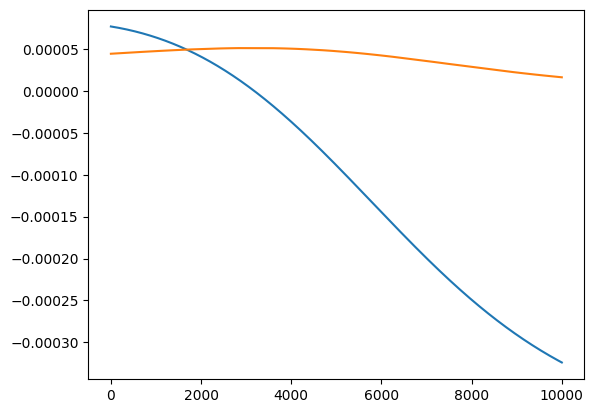

In [40]:
b_firstorder = []
b_secondorder = []
for i in range(len(b_sim[:,alpha])):
    b_firstorder.append((1/tau)*dnE_dbn(args, 1, u, b_sim[i,alpha], alpha))
    b_secondorder.append((1/tau)*dnE_dbn(args, 2, u, b_sim[i,alpha], alpha))
    
plt.plot(b_secondorder)
plt.plot(np.gradient(b_sim[:,alpha],2))

In [ ]:
plt.plot(np.gradient(b_sim[:,alpha],1))
plt.plot()

In [25]:
grad_sim(args, u, b, alpha)

0.10008967972479059

In [26]:
b_sim[1, alpha]

0.10008850368441087

In [27]:
(1-b_sim[t, alpha])/tau

0.000149999998378817

In [1232]:
(1/tau)*dE_db/2

9.150000011672576e-05

In [1226]:
np.gradient(np.gradient(b_sim[:3,alpha],1), 1)

array([1.67608147e-08, 1.67608147e-08, 1.67608147e-08])

In [1201]:
((1/tau)*dE_db/np.gradient(b_sim[:2,alpha],2)[0]) #/1.010499076220878

2.020998152441756

In [1150]:
f = np.gradient(b_sim[:2,alpha],1)[0]
dfdb = d2E_db2 * f
print(dfdb)
print(np.gradient(b_sim[:2,alpha],2)[0])

0.00038512468190950616
9.039976204656963e-05


In [10]:
def dnE_dbn(args, n, u, b, alpha):
    T = args.trajectory_length
    inner_sum_term = 0
    for i in range(1, T-n+1):
        prod_term_1 = (T-i)
        for j in range(1, n):
            prod_term_1 = prod_term_1*(T-i-j)
        inner_sum_term += prod_term_1*u*args.S[i-1, alpha, alpha].detach().numpy()*(b**(T-i-n))
    
    for i in range(1, int((2*T-n)/2)+1):
        prod_term_2 = (T-i)
        for j in range(1, n):
            prod_term_2 = prod_term_2*(2*T-2*i-j)
        inner_sum_term -= prod_term_2*(u**2)*(b**(2*T-2*i-n))

    return inner_sum_term    

In [28]:
def recurrent_solution_steps_3(args, step_size): 
    tau = (args.num_samples*args.output_size)/(args.lr)
    T = args.trajectory_length
    b_pred = np.zeros((args.num_SV, args.num_epochs))
    for alpha in range(args.num_SV):
        for e in range(0, int(args.num_epochs/step_size)):
            for step in range(0, step_size):
                if e == 0 and step == 0:
                    b = args.rec_mode_init[alpha].detach().numpy()
                    b_pred[alpha,e] = b
                else:
                    if step == 0 and e > 0:
                        b = b_pred[alpha,e*step_size + step -1]
                    u = args.inout_mode_init[alpha].detach().numpy()
                    sum_term = 0
                    dE_db = dnE_dbn(args, 1, u, b, alpha)
                    d2E_db2 = dnE_dbn(args, 2, u, b, alpha)
                    d3E_db3 = dnE_dbn(args, 3, u, b, alpha)
                    d4E_db4 = dnE_dbn(args, 4, u, b, alpha)
                    d5E_db5 = dnE_dbn(args, 5, u, b, alpha)
                    
                    
                    sum_term += dE_db * ((step/tau)**1)/(math.factorial(1)) # first-order
                    sum_term += d2E_db2*dE_db * ((step/tau)**2)/(math.factorial(2)) # second-order
                    sum_term += ((d2E_db2**2)*dE_db + d3E_db3*(dE_db**2)) * ((step/tau)**3)/(math.factorial(3)) # third-order
                    sum_term += (4*d2E_db2*d3E_db3*(dE_db**2) + (d2E_db2**3)*dE_db + d4E_db4*(dE_db**3))* ((step/tau)**4)/(math.factorial(4))
                    
#                     5th order
                    fifth_order = 8*(d2E_db2**2)*d3E_db3*(dE_db**2) + 4*d2E_db2*d4E_db4*(dE_db**3) + 4*(d3E_db3**2)*(dE_db**3)
                    fifth_order += (d2E_db2**4)*dE_db + 3*d2E_db2*d3E_db3*(dE_db**2) + 3*d4E_db4*d2E_db2*(dE_db**2) + d5E_db5*(dE_db**4)
                    sum_term += fifth_order * ((step/tau)**5)/(math.factorial(5))
            
                    b_pred[alpha,e*step_size + step] = b + sum_term
    return b_pred

In [31]:
b_pred = recurrent_solution_steps_3(args, 5000)

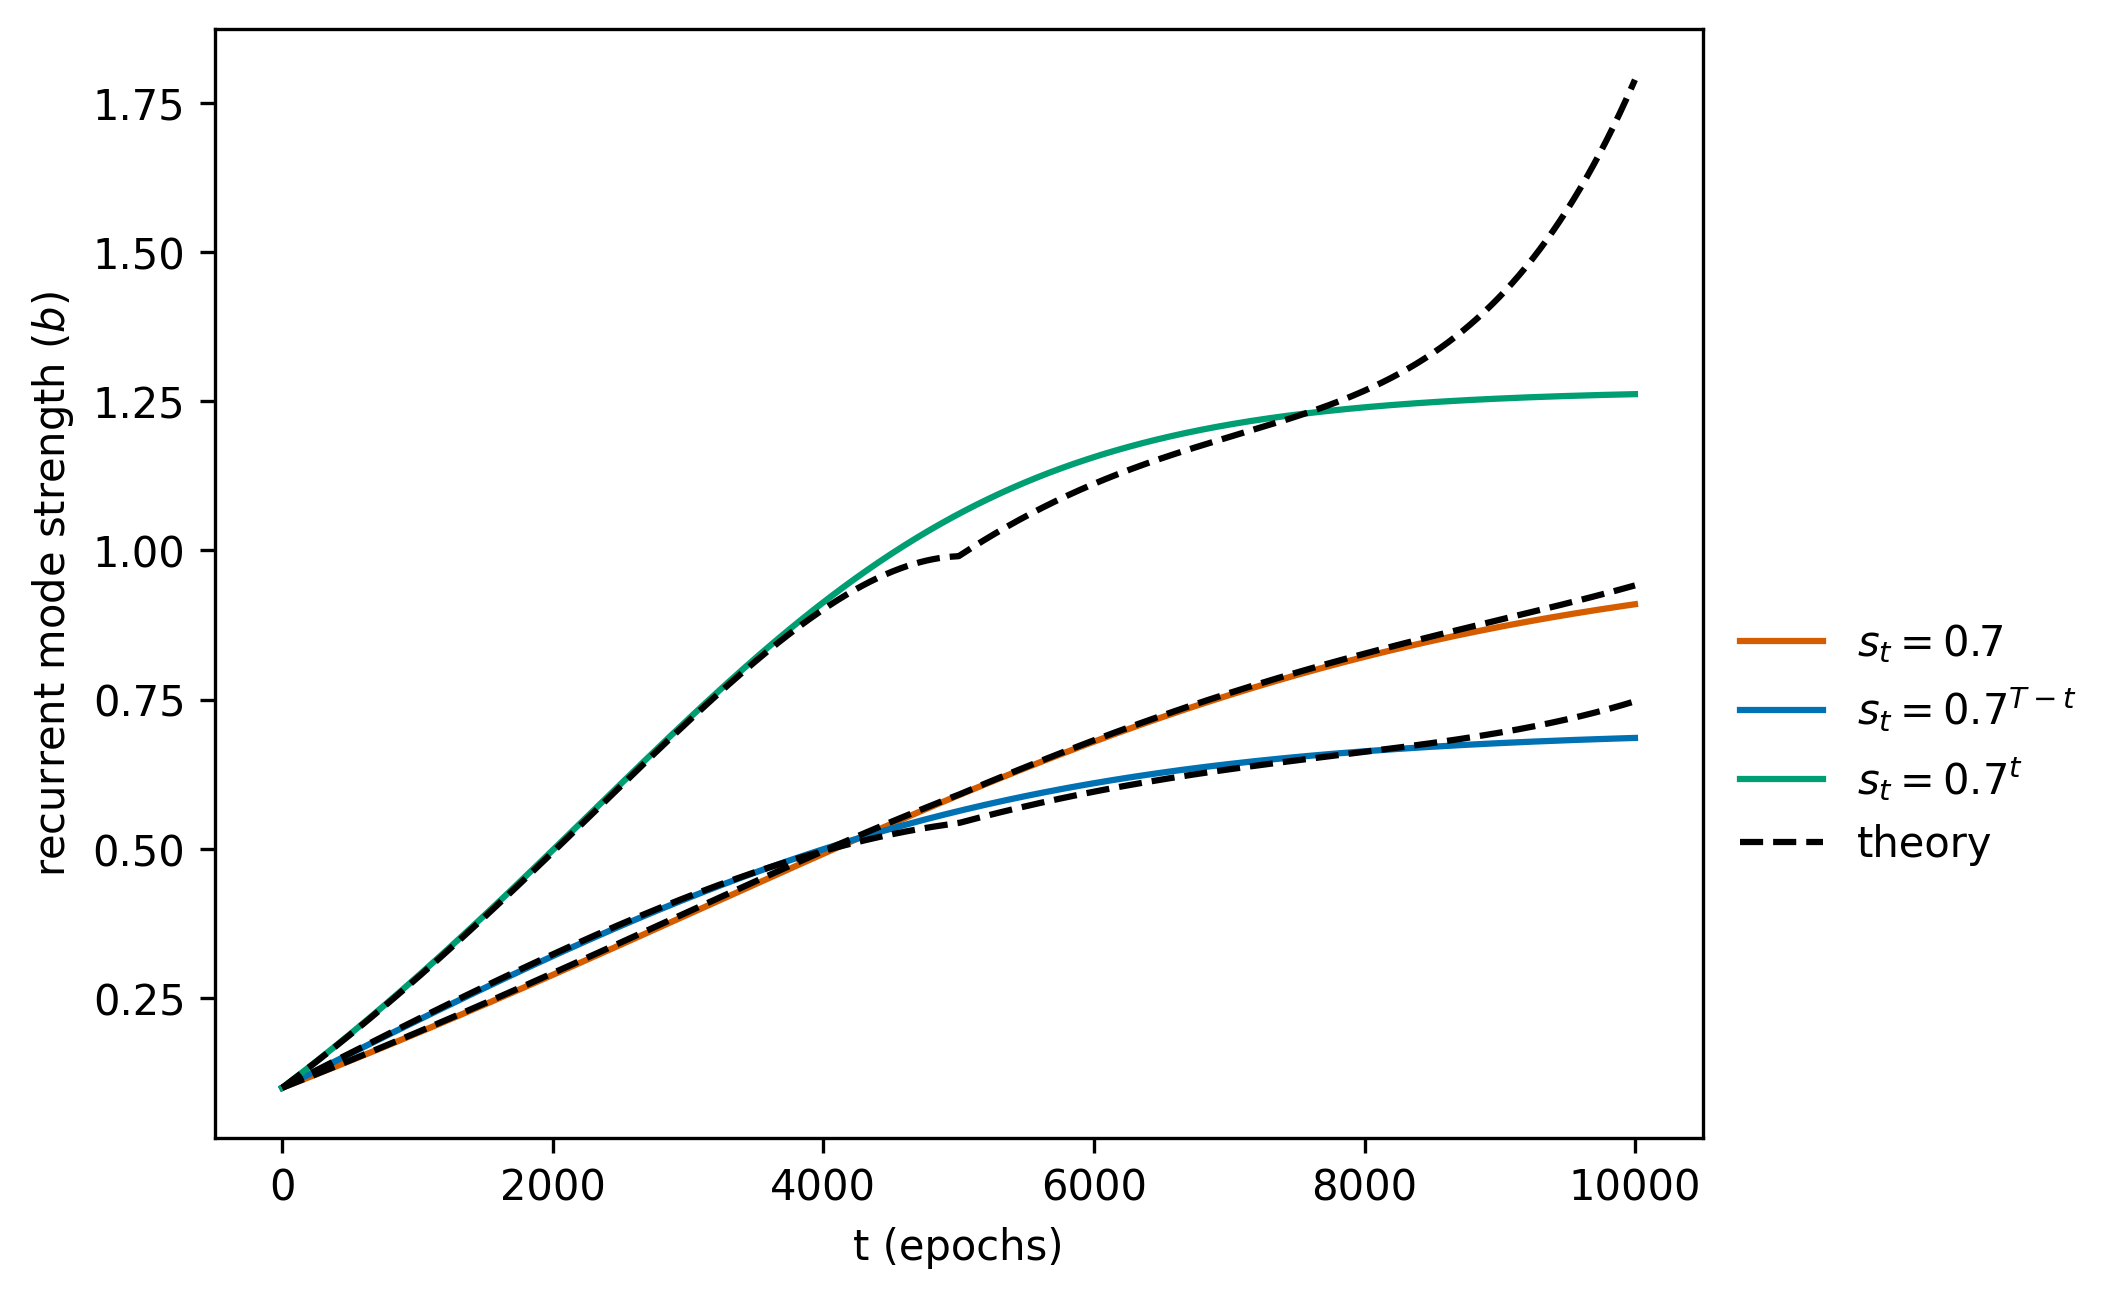

In [32]:
fig = plt.figure(dpi=300)
ax = fig.add_subplot(111)
plt.plot(b_sim[:,0], label=r'$s_t=0.7$', color=blind_colors[0])
plt.plot(b_sim[:,1], label=r'$s_t=0.7^{T-t}$', color=blind_colors[1])
plt.plot(b_sim[:,2], label=r'$s_t=0.7^t$', color=blind_colors[2])
plt.plot(b_pred[0], ls='dashed', color='black')
plt.plot(b_pred[1], ls='dashed', color='black')
plt.plot(b_pred[2], ls='dashed',label='theory', color='black')
ax.set_xlabel('t (epochs)')
ax.set_ylabel(r'recurrent mode strength ($b$)')
ax.legend(frameon=False, bbox_to_anchor=(1, 0.5))
# ax.set_yticks([0.0, 0.2])

# Full solution?

In [932]:
parser = argparser.get_parser()  
args = parser.parse_args('')
args.frozen_input_output = False
args.frozen_hidden_layer = False
args.zerobalanced = True
args.input_size = 3
args.hidden_size = 3
args.output_size = 3
args.num_seeds = 1
args.num_SV = 3
args.trajectory_length=3
args.inout_mode_init = [0.1, 0.1, 0.1]
args.rec_mode_init = [0.1, 0.1, 0.1] 
args.lr = 10
args.num_epochs = 10000

In [933]:
S = torch.zeros((args.trajectory_length, args.output_size, args.input_size)) 
for t in range(1, args.trajectory_length+1):
    t_S = torch.tensor([0.7, 0.7**(args.trajectory_length-t), 1.1**t]) #  0.7**t, 
    S[t-1] = torch.diag(t_S) 
    # soln for b at [1, 0.7, 1/1.1 ~0.9]
args.S = S
args.num_seeds = 1

args, X, y = utils.generate_data(args)

tape = utils.get_tape_module(args)

args.inout_mode_init = torch.tensor(args.inout_mode_init)
args.rec_mode_init = torch.tensor(args.rec_mode_init)

W_x, W_h, W_y, dW_x, dW_h, dW_y, R_y, R_x = utils.initialize_student(args)

tape.W_x[0,0] = W_x.detach().numpy()
tape.W_h[0,0] = W_h.detach().numpy()
tape.W_y[0,0] = W_y.detach().numpy()
tape.dW_x[0,0] = dW_x.detach().numpy()
tape.dW_h[0,0] = dW_h.detach().numpy()
tape.dW_y[0,0] = dW_y.detach().numpy()
tape.R_y[0,0] = R_y.detach().numpy()
tape.R_x[0,0] = R_x.detach().numpy()

tensor(0.5926)
tensor(0.6790)
tensor(0.7037)


In [934]:
model = linear_RNN.LinearRNN(args, init_W_x = W_x, init_W_h = W_h, init_W_y = W_y)
losses, W_x_ar, W_h_ar, W_y_ar, H_ar, W_x_grad_ar, W_h_grad_ar = model.train(X,y) ## add tape to model
a_sim,b_sim,c_sim,u_sim = model.project_SVD_space(W_x_ar, W_h_ar, W_y_ar, tape)

In [731]:
def full_solution_steps(args, step_size): 
    tau = (args.num_samples*args.output_size)/args.lr
    T = args.trajectory_length
    b_pred = np.zeros((args.num_SV, args.num_epochs))
    u_pred = np.zeros((args.num_SV, args.num_epochs))
    for alpha in range(args.num_SV):
        for e in range(0, int(args.num_epochs/step_size)):
            for step in range(0, step_size):
                if e == 0 and step == 0:
                    b = args.rec_mode_init[alpha]
                    b_pred[alpha,e] = b
                    u = args.inout_mode_init[alpha]
                    u_pred[alpha,e] = u
                else:
                    if step == 0 and e > 0:
                        b = b_pred[alpha,e*step_size + step -1]
                        u = u_pred[alpha,e*step_size + step -1]
                    sum_term = 0
                    for n in range(1,T): #N # first-order approximation works very well
                        inner_sum_term = 0
                        for i in range(1, T-n+1):
                            if n == 1:
                                inner_sum_term += (T-i)*u*args.S[i-1, alpha, alpha]*(b**(T-i-1))
                                inner_sum_term -= (T-i)*(u**2)*(b**(2*T-2*i-1))
                            else:
                                inner_sum_term += (math.factorial(T-i)/math.factorial(T-i-n))*u*args.S[i-1, alpha, alpha]*(b**(T-i-n))
                                inner_sum_term -= (((T-i)*math.factorial(2*T-2*i-1))/(math.factorial(2*T-2*i-n)))*(u**2)*(b**(2*T-2*i-n))
                        sum_term += (inner_sum_term * ((step/tau)**n)/(math.factorial(n)))
                    b_pred[alpha,e*step_size + step] = b + sum_term
                    u_sum_term = 0
                    for i in range(1, T+1):
                        u_sum_term += ((b_pred[alpha,e*step_size + step])**(T-i))*args.S[i-1, alpha, alpha]*u
                        u_sum_term -= ((b_pred[alpha,e*step_size + step])**(2*T-2*i))*(u**2)
                    u_pred[alpha,e*step_size + step] = u + 2*u_sum_term*(step/tau)
    return u_pred, b_pred

In [935]:
u_pred, b_pred = full_solution_steps(args, 100)

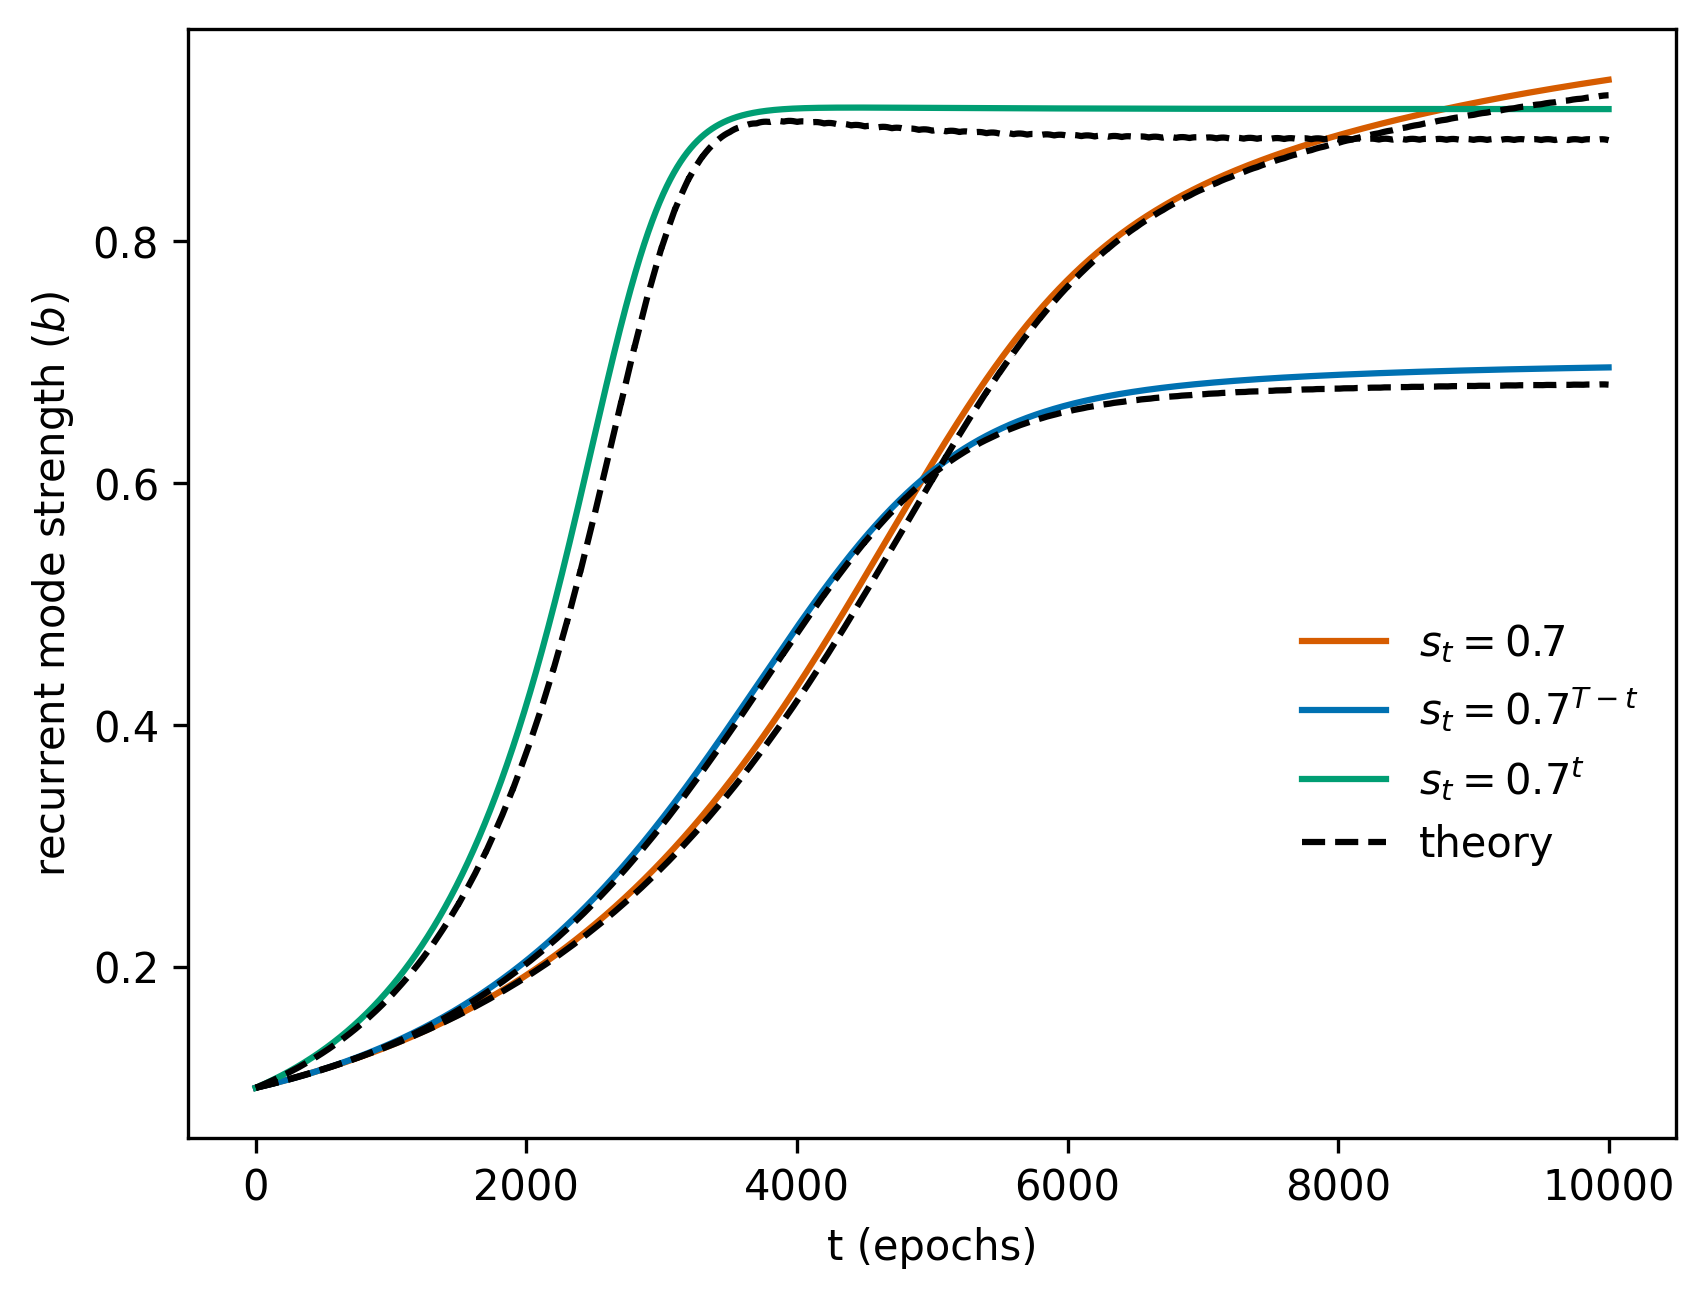

In [936]:
fig = plt.figure(dpi=300)
ax = fig.add_subplot(111)
plt.plot(b_sim[:,0], label=r'$s_t=0.7$', color=blind_colors[0])
plt.plot(b_sim[:,1], label=r'$s_t=0.7^{T-t}$', color=blind_colors[1])
plt.plot(b_sim[:,2], label=r'$s_t=0.7^t$', color=blind_colors[2])
plt.plot(b_pred[0][:], ls='dashed', color='black')
plt.plot(b_pred[1][:], ls='dashed', color='black')
plt.plot(b_pred[2][:], ls='dashed',label='theory', color='black')
ax.set_xlabel('t (epochs)')
ax.set_ylabel(r'recurrent mode strength ($b$)')
ax.legend(frameon=False, bbox_to_anchor=(1, 0.5))
# ax.set_yticks([0.0, 0.2])

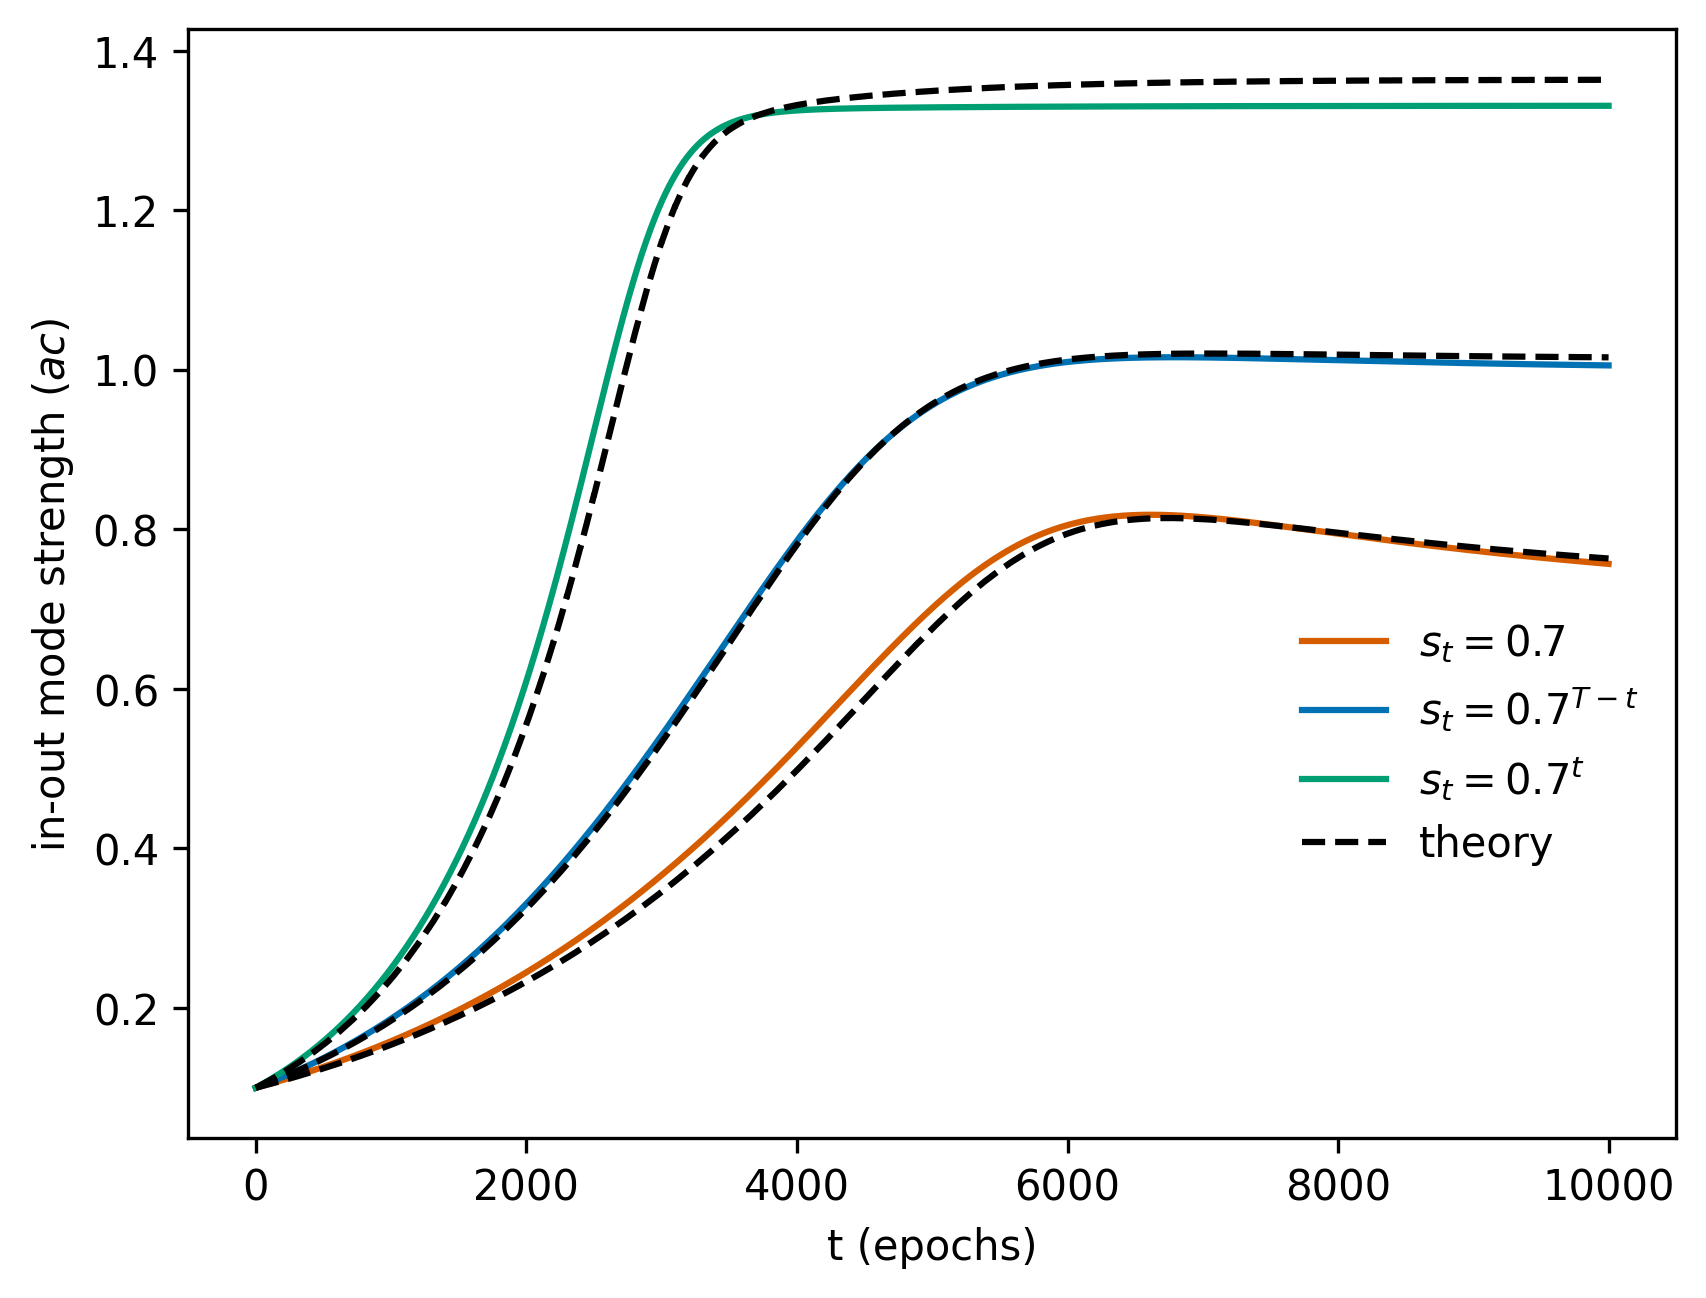

In [937]:
fig = plt.figure(dpi=300)
ax = fig.add_subplot(111)
plt.plot(u_sim[:,0], label=r'$s_t=0.7$', color=blind_colors[0])
plt.plot(u_sim[:,1], label=r'$s_t=0.7^{T-t}$', color=blind_colors[1])
plt.plot(u_sim[:,2], label=r'$s_t=0.7^t$', color=blind_colors[2])
plt.plot(u_pred[0], ls='dashed', color='black')
plt.plot(u_pred[1], ls='dashed', color='black')
plt.plot(u_pred[2], ls='dashed',label='theory', color='black')
ax.set_xlabel('t (epochs)')
ax.set_ylabel(r'in-out mode strength ($ac$)')
ax.legend(frameon=False, bbox_to_anchor=(1, 0.5))
# ax.set_yticks([0.0, 0.2])